In [2]:
from db_queries import get_ids, get_population, get_covariate_estimates, get_best_model_versions, get_outputs
from get_draws.api import get_draws
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt

# Back-of-the-envelope: CVD and ambient PM pollution
How many additional CVD deaths (or some other outcome measure?) will there be with an increase in air pollution levels in Washington State?

- A = CVD deaths (or another outcome metric?)  
- B = Effect of air pollution on CVD outcomes (separate RRs for IHD and stroke? Other forms of CVD?) 
- C = Change in air pollution levels (what units? From FHS estimate?)



``A * B * C = X``, where X is the additional deaths with each C increase in air pollution levels 

Related links: 
- [Ambient PM pollution Methods Appendix 2021](https://www.healthdata.org/gbd/methods-appendices-2021/ambient-particulate-matter-pollution)
- [Syl's B-O-E calculation notebook from CVD sim](https://github.com/ihmeuw/vivarium_research_nih_us_cvd/blob/main/data_testing_exploration/Back_of_envelope.ipynb)
- [SharePoint notes](https://uwnetid.sharepoint.com/sites/ihme_simulation_science_team/_layouts/15/doc.aspx?sourcedoc={89f5b873-f051-4e2f-9032-9d5a42c59bda}&action=edit)
- [Abie's slides on B-O-E calculations](https://www.dropbox.com/scl/fi/04fy98nlj158wlpw44peb/vivarium_back_of_envelop_method.pptx?rlkey=v8n9m0qi2ts2k3k0c836dhp7z&e=1&dl=0)
- [CVD Concept Model docs](https://vivarium-research.readthedocs.io/en/latest/models/concept_models/vivarium_us_cvd/concept_model.html)

# First calculation: How many CVD deaths are currently attributable to ambient air pollution? 
``CVD deaths due to air pollution = total CVD deaths * air pollution PAF``

First, I am going to focus on the 50-69 years age group and males, but this population is quite small and this calculation would be more interesting if I include all age groups and sexes.

In [3]:
# CVD deaths (count) in Washington State in 2021 for 50-69 year old males
cvd_deaths = get_draws(location_id=570, # Washington State
         gbd_id_type='cause_id',
         gbd_id=[491,493,495,496,497], # 491 is overall CVD cause
         source='codcorrect',
         year_id=2021,
         release_id=9,
         measure_id=1,
         metric_id=1,
         age_group_id=[16,17,18,19,20,21], # age groups comprising 50-80+ year olds
         sex_id=[1,2] 
         )
cvd_deaths

#  cause_id=493 is Ischemic Heart Disease
#  cause_id=495 is Ischemic Stroke
#  cause_id=496 is Intracerebral Hemorrhage
#  cause_id=497 is Subarachnoid Hemorrhage

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/get_draws/api.py:194: UserWarning: No version_id was specified, so get_draws will automatically determine a best version ID to use from the given parameters. If you want to retrieve a specific version please pass a version_id directly.
  warnings.warn(


,age_group_id,cause_id,draw_0,draw_1,draw_10,draw_100,draw_101,draw_102,draw_103,draw_104,...,draw_96,draw_97,draw_98,draw_99,location_id,measure_id,sex_id,year_id,metric_id,version_id
0,16,491,162.006047,175.970154,173.867321,174.081368,184.390754,220.267901,183.262039,148.432848,...,177.903552,177.905815,165.828469,209.906636,570,1,2,2021,1,393
1,16,493,65.844271,81.849440,76.896772,72.852052,85.561863,90.809349,85.520046,63.462186,...,78.225666,82.558823,67.583828,92.543445,570,1,2,2021,1,393
2,16,495,6.100270,5.699763,5.374150,6.454084,5.373510,8.092491,5.208867,5.396392,...,6.165807,6.282064,7.207766,7.150270,570,1,2,2021,1,393
3,16,496,19.400072,18.049368,17.155056,20.633377,17.049754,26.710358,16.623925,16.972362,...,19.374355,20.391285,22.311171,22.150169,570,1,2,2021,1,393
4,16,497,14.329786,13.222935,13.048596,14.250484,14.497830,18.502367,12.848939,11.408347,...,17.623151,13.688130,14.783512,18.474858,570,1,2,2021,1,393
5,17,491,266.258528,282.030760,276.754674,280.637655,323.886678,365.962300,301.038590,260.711352,...,327.073632,286.181560,263.818187,361.724037,570,1,2,2021,1,393
6,17,493,117.709027,149.591214,129.249195,127.255045,163.419072,161.833894,144.706240,118.827820,...,150.429075,135.529022,127.316111,166.506738,570,1,2,2021,1,393
7,17,495,18.103315,13.461464,16.738010,19.287898,18.913007,21.221435,17.335530,17.264521,...,22.006699,18.237391,14.496200,22.452610,570,1,2,2021,1,393
8,17,496,32.056128,24.067153,30.228206,30.920579,31.748638,43.651553,33.835052,27.591490,...,37.839418,32.868609,26.719644,47.398648,570,1,2,2021,1,393
9,17,497,15.663828,11.559557,13.714925,14.332422,15.119470,17.451037,16.478789,12.402641,...,18.422577,15.191863,11.746855,17.513007,570,1,2,2021,1,393


In [ ]:
%%time

# Ambient air pollution PAF
air_pm_paf = get_draws(location_id=570, # Washington State
         gbd_id_type='rei_id',
         gbd_id=86, # Ambient particulate matter pollution
         source='burdenator', 
         year_id=2021,
         release_id=9,
         measure_id=4,
         metric_id=1, # 2 (rate) results in an error, so I need to convert these to a rate
         age_group_id=[16,17,18,19,20,21], # age groups comprising 50-80+ year olds
         sex_id=[1,2]
         )

air_pm_paf = air_pm_paf_count.set_index(['age_group_id','cause_id','location_id','year_id','measure_id','metric_id','sex_id','rei_id'])
air_pm_paf_count
# This call should return the ambient air pollution PAF. It returns rates of YLDs (measure_id = 3) and YLLs (measure_id = 4), but I am 
# filtering to YLLs because I am looking at CVD mortality not morbidity.

# There is no ambient air pollution PAF for CVD as an umbrella cause, so doing each of the sub-causes separately.

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/get_draws/api.py:194: UserWarning: No version_id was specified, so get_draws will automatically determine a best version ID to use from the given parameters. If you want to retrieve a specific version please pass a version_id directly.
  warnings.warn(


CPU times: user 4.5 s, sys: 3.95 s, total: 8.45 s
Wall time: 15.9 s


draw_0  \
age_group_id cause_id location_id year_id measure_id metric_id sex_id rei_id               
16           294      570         2021    4          1         1      86      702.506126   
                                                               2      86      357.472542   
             295      570         2021    4          1         1      86        8.092762   
                                                               2      86        6.914116   
             322      570         2021    4          1         1      86        8.092762   
...                                                                                  ...   
21           956      570         2021    4          1         2      86       44.798300   
             974      570         2021    4          1         2      86      136.107233   
             976      570         2021    4          1         2      86      136.107233   
             1029     570         2021    4          1         2      86      198.547969   
             1059     570         2021    4          1         2      86      198.547969   

                                                                                 draw_1  \
age_group_id cause_id location_id year_id measure_id metric_id sex_id rei_id              
16           294      570         2021    4          1         1      86      54.221967   
                                                               2      86      42.757343   
             295      570         2021    4          1         1      86       2.238937   
                                                               2      86       2.679324   
             322      570         2021    4          1         1      86       2.238937   
...                                                                                 ...   
21           956      570         2021    4          1         2      86      16.486861   
             974      570         2021    4          1         2      86      13.872062   
             976      570         2021    4          1         2      86      13.872062   
             1029     570         2021    4          1         2      86      26.297290   
             1059     570         2021    4          1         2      86      26.297290   

                                                                                  draw_2  \
age_group_id cause_id location_id year_id measure_id metric_id sex_id rei_id               
16           294      570         2021    4          1         1      86      411.842284   
                                                               2      86      219.317585   
             295      570         2021    4          1         1      86       10.485625   
                                                               2      86        7.288680   
             322      570         2021    4          1         1      86       10.485625   
...                                                                                  ...   
21           956      570         2021    4          1         2      86       44.912346   
             974      570         2021    4          1         2      86       67.497616   
             976      570         2021    4          1         2      86       67.497616   
             1029     570         2021    4          1         2      86      108.501262   
             1059     570         2021    4          1         2      86      108.501262   

                                                                                  draw_3  \
age_group_id cause_id location_id year_id measure_id metric_id sex_id rei_id               
16           294      570         2021    4          1         1      86      143.764997   
                                                               2      86       68.855501   
             295      570         2021    4          1         1      86        5.437164   
                                            

In [6]:
air_pm_paf_count = air_pm_paf_count.loc[air_pm_paf_count.index.get_level_values('cause_id').isin([493, 495, 496, 497])]
draw_cols = [col for col in air_pm_paf_count.columns if col.startswith('draw_')]
air_pm_paf = air_pm_paf_count.copy()
air_pm_paf[draw_cols] = air_pm_paf[draw_cols] / 1000 
air_pm_paf

draw_0  \
age_group_id cause_id location_id year_id measure_id metric_id sex_id rei_id             
16           493      570         2021    4          1         1      86      0.355441   
                                                               2      86      0.097656   
             495      570         2021    4          1         1      86      0.011223   
                                                               2      86      0.006527   
             496      570         2021    4          1         1      86      0.034013   
                                                               2      86      0.020700   
             497      570         2021    4          1         1      86      0.016543   
                                                               2      86      0.015137   
17           493      570         2021    4          1         1      86      0.546145   
                                                               2      86      0.151936   
             495      570         2021    4          1         1      86      0.025455   
                                                               2      86      0.016703   
             496      570         2021    4          1         1      86      0.037175   
                                                               2      86      0.029509   
             497      570         2021    4          1         1      86      0.010273   
                                                               2      86      0.014415   
18           493      570         2021    4          1         1      86      0.601345   
                                                               2      86      0.208860   
             495      570         2021    4          1         1      86      0.028254   
                                                               2      86      0.015975   
             496      570         2021    4          1         1      86      0.049928   
                                                               2      86      0.030525   
             497      570         2021    4          1         1      86      0.012635   
                                                               2      86      0.013991   
19           493      570         2021    4          1         1      86      0.554406   
                                                               2      86      0.253006   
             495      570         2021    4          1         1      86      0.047555   
                                                               2      86      0.052983   
             496      570         2021    4          1         1      86      0.049314   
                                                               2      86      0.041459   
             497      570         2021    4          1         1      86      0.007227   
                                                               2      86      0.013632   
20           493      570         2021    4          1         1      86      0.470827   
                                                               2      86      0.245775   
             495      570         2021    4          1         1      86      0.050956   
                                                               2      86      0.060400   
             496      570         2021    4          1         1      86      0.049969   
                                                               2      86      0.041725   
             497      570         2021    4          1         1      86      0.006750   
                                                               2      86      0.012335   
21           493      570         2021    4          1         1      86      0.995922   
             495      570         2021    4          1         1      86      0.197181   
             496      570         2021    4          1         1      86      0.064218   
             497      570     

In [5]:
# Is there a difference between Particulate matter pollution (rei_id=380) and Ambient particulate matter pollution (rei_id=86)?

# What is the difference between the call from source='paf' and source='burdenator'?
# Answer: Because age/sex/location/cause aggregation of attributable burden doesn’t occur until the burdenator and risk aggregation 
# happens between running save_results_risk on the PAF draws and running the burdenator, age/sex/location/cause/rei aggregates are 
# missing from the “paf” source. If you want aggregates, burdenator would be a better option! (https://scicomp-docs.ihme.washington.edu/get_draws/current/sources.html#paf)


In [9]:
# Calculate CVD deaths attributable to air pollution for each age group and sex combination
results_list = []

# Create mappings for display purposes
age_group_map = {16: '50-54', 17: '55-59', 18: '60-64', 19: '65-69', 20: '70-74', 21: '75-79'}
sex_map = {1: 'Male', 2: 'Female'}

# Get unique combinations of age group and sex
age_sex_combinations = cvd_deaths[['age_group_id', 'sex_id']].drop_duplicates()

for _, combo in age_sex_combinations.iterrows():
    age_id = combo['age_group_id']
    sex_id = combo['sex_id']
    
    # Filter data for this specific age/sex combination
    cvd_subset = cvd_deaths[(cvd_deaths['age_group_id'] == age_id) & (cvd_deaths['sex_id'] == sex_id)]
    paf_subset = air_pm_paf.loc[(air_pm_paf.index.get_level_values('age_group_id') == age_id) & 
                                      (air_pm_paf.index.get_level_values('sex_id') == sex_id)]
    
    # 1. Get total deaths for each sub-cause (e.g., IHD, stroke, etc.)
    subcause_deaths = cvd_subset[cvd_subset['cause_id'].isin([493, 495, 496, 497])]
    draw_cols = [col for col in subcause_deaths.columns if col.startswith('draw_')]
    
    # 2. Sum deaths across sub-causes for each draw
    total_subcause_deaths = subcause_deaths[draw_cols].sum()
    
    # 3. Calculate the proportion of deaths for each sub-cause and draw
    proportions = subcause_deaths.set_index('cause_id')[draw_cols].div(total_subcause_deaths)
    
    # 4. Get the PAF for each sub-cause and draw
    subcause_pafs = paf_subset.reset_index().set_index('cause_id')[draw_cols]
    
    # 5. Calculate weighted PAF for each draw
    weighted_paf = (proportions * subcause_pafs).sum()
    
    # 6. Get overall CVD deaths (cause_id=491)
    overall_cvd_deaths = cvd_subset[cvd_subset['cause_id'] == 491][draw_cols].iloc[0]
    
    # 7. Calculate overall CVD deaths due to air pollution for each draw
    cvd_deaths_due_to_air_pm = overall_cvd_deaths * weighted_paf
    
    # 8. Summarize results for this age/sex combination
    mean = cvd_deaths_due_to_air_pm.mean()
    lower = cvd_deaths_due_to_air_pm.quantile(0.025)
    upper = cvd_deaths_due_to_air_pm.quantile(0.975)
    total_deaths = overall_cvd_deaths.sum()
    percentage_attr = (mean / total_deaths) * 100
    
    results_list.append({
        'age_group_id': age_id,
        'sex_id': sex_id, 
        'age_group_name': age_group_map.get(age_id, str(age_id)),
        'sex_name': sex_map.get(sex_id, str(sex_id)),
        'attributable_deaths_mean': mean,
        'attributable_deaths_lower': lower,
        'attributable_deaths_upper': upper,
        'total_cvd_deaths': total_deaths,
        'percentage_attributable': percentage_attr
    })
    
    print(f"{age_group_map.get(age_id, str(age_id))} {sex_map.get(sex_id, str(sex_id))}: {mean:.2f} deaths (95% CI: {lower:.2f}-{upper:.2f}), {percentage_attr:.2f}% of CVD deaths")

# Create results DataFrame
results_df = pd.DataFrame(results_list)
print(f"\nTotal attributable deaths across all groups: {results_df['attributable_deaths_mean'].sum():.1f}")
print(f"Total CVD deaths across all groups: {results_df['total_cvd_deaths'].sum():.0f}")
print(f"Overall percentage attributable: {(results_df['attributable_deaths_mean'].sum() / results_df['total_cvd_deaths'].sum()) * 100:.2f}%")


# The 50-54 Male category is about 10X higher than the last notebook, did I need to convert the PAFs to rates by dividing by 10000 instead of 1000?

50-54 Female: 8.55 deaths (95% CI: 1.53-21.46), 0.01% of CVD deaths
55-59 Female: 21.19 deaths (95% CI: 4.00-51.87), 0.01% of CVD deaths
60-64 Female: 39.30 deaths (95% CI: 7.18-93.06), 0.02% of CVD deaths
65-69 Female: 71.35 deaths (95% CI: 13.78-165.49), 0.02% of CVD deaths
70-74 Female: 86.23 deaths (95% CI: 16.10-201.25), 0.02% of CVD deaths
50-54 Male: 81.74 deaths (95% CI: 13.55-201.95), 0.04% of CVD deaths
55-59 Male: 195.83 deaths (95% CI: 33.58-481.55), 0.06% of CVD deaths
60-64 Male: 266.04 deaths (95% CI: 44.32-633.15), 0.06% of CVD deaths
65-69 Male: 288.75 deaths (95% CI: 50.07-706.09), 0.05% of CVD deaths
70-74 Male: 251.59 deaths (95% CI: 44.59-576.89), 0.04% of CVD deaths
75-79 Male: 1715.81 deaths (95% CI: 303.33-4000.16), 0.08% of CVD deaths
75-79 Female: 1989.99 deaths (95% CI: 348.78-4631.84), 0.07% of CVD deaths

Total attributable deaths across all groups: 5016.4
Total CVD deaths across all groups: 8332653
Overall percentage attributable: 0.06%


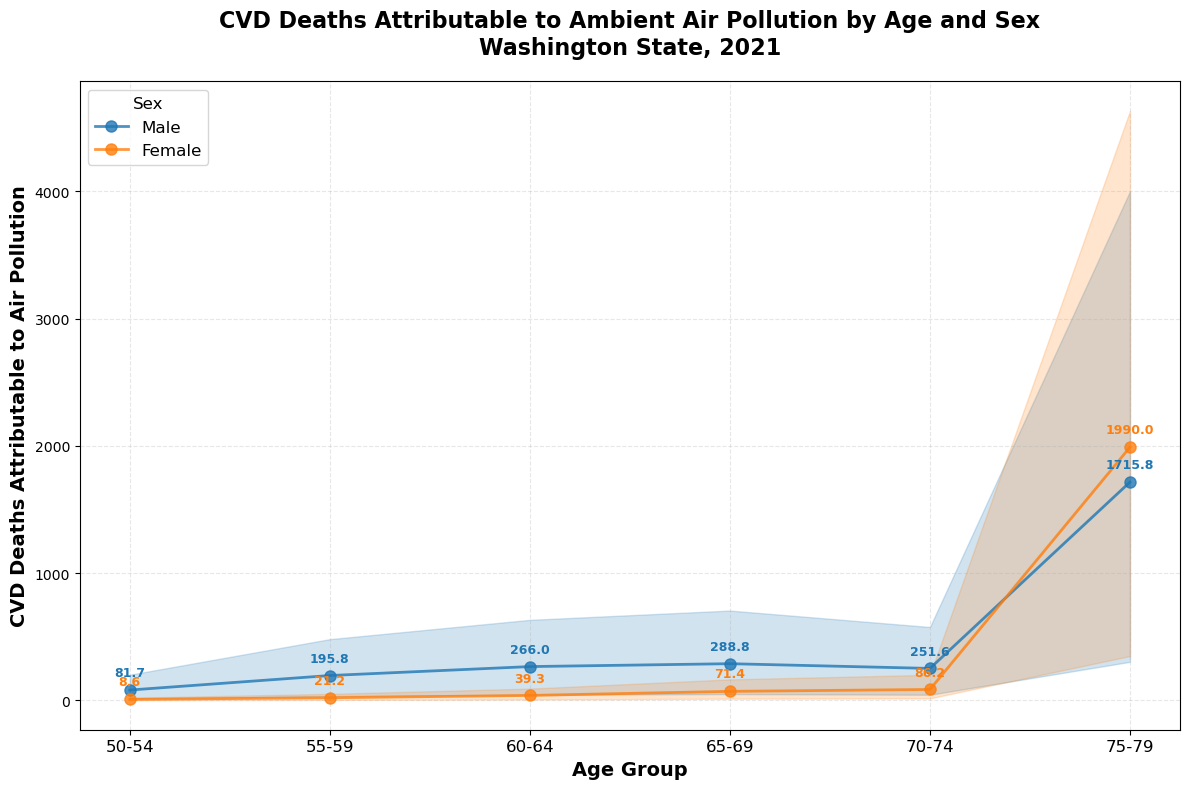


SUMMARY STATISTICS
Total CVD deaths (ages 50-79): 8332653
Deaths attributable to air pollution: 5016.4
Overall percentage attributable: 0.06%

By Sex:
  Male: 2799.8 attributable deaths (0.07%)
  Female: 2216.6 attributable deaths (0.05%)


In [10]:

# Plot CVD deaths attributable to air pollution by age group and sex
import matplotlib.pyplot as plt
import numpy as np

# Check if we have results to plot
if 'results_df' in locals() and not results_df.empty:
    
    # Create ordered age categories for plotting
    ordered_ages = sorted(results_df['age_group_name'].unique(), 
                         key=lambda x: results_df[results_df['age_group_name']==x]['age_group_id'].iloc[0])
    results_df['age_group_name'] = pd.Categorical(
        results_df['age_group_name'], categories=ordered_ages, ordered=True
    )
    results_df_sorted = results_df.sort_values(['age_group_name', 'sex_name'])
    
    # Create the plot
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Define colors for male and female
    colors = {'Male': '#1f77b4', 'Female': '#ff7f0e'}
    
    # Plot lines for each sex
    for sex in ['Male', 'Female']:
        subset = results_df_sorted[results_df_sorted['sex_name'] == sex]
        x = range(len(subset))  # Use numeric positions for x-axis
        y = subset['attributable_deaths_mean']
        lower = subset['attributable_deaths_lower'] 
        upper = subset['attributable_deaths_upper']
        
        # Plot the line with markers
        ax.plot(x, y, label=sex, marker='o', linewidth=2, markersize=8, 
                color=colors[sex], alpha=0.8)
        
        # Add confidence intervals as shaded area
        ax.fill_between(x, lower, upper, alpha=0.2, color=colors[sex])
        
        # Add value labels on points
        for i, (xi, yi) in enumerate(zip(x, y)):
            ax.annotate(f'{yi:.1f}', (xi, yi), textcoords="offset points", 
                       xytext=(0,10), ha='center', fontsize=9, 
                       color=colors[sex], fontweight='bold')
    
    # Customize the plot
    ax.set_xlabel('Age Group', fontsize=14, fontweight='bold')
    ax.set_ylabel('CVD Deaths Attributable to Air Pollution', fontsize=14, fontweight='bold')
    ax.set_title('CVD Deaths Attributable to Ambient Air Pollution by Age and Sex\nWashington State, 2021', 
                fontsize=16, fontweight='bold', pad=20)
    
    # Set x-axis labels to age group names
    age_labels = results_df_sorted[results_df_sorted['sex_name'] == 'Male']['age_group_name'].tolist()
    ax.set_xticks(range(len(age_labels)))
    ax.set_xticklabels(age_labels, fontsize=12)
    
    # Add legend
    ax.legend(title='Sex', fontsize=12, title_fontsize=12, loc='upper left')
    
    # Add grid for easier reading
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Improve layout
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\n" + "="*60)
    print("SUMMARY STATISTICS")
    print("="*60)
    
    total_deaths = results_df['total_cvd_deaths'].sum()
    total_attributable = results_df['attributable_deaths_mean'].sum()
    overall_pct = (total_attributable/total_deaths)*100
    
    print(f"Total CVD deaths (ages 50-79): {total_deaths:.0f}")
    print(f"Deaths attributable to air pollution: {total_attributable:.1f}")
    print(f"Overall percentage attributable: {overall_pct:.2f}%")
    
    # Summary by sex
    print(f"\nBy Sex:")
    sex_summary = results_df.groupby('sex_name').agg({
        'attributable_deaths_mean': 'sum',
        'total_cvd_deaths': 'sum'
    })
    for sex in ['Male', 'Female']:
        attr_deaths = sex_summary.loc[sex, 'attributable_deaths_mean']
        total_deaths_sex = sex_summary.loc[sex, 'total_cvd_deaths']
        pct = (attr_deaths/total_deaths_sex)*100
        print(f"  {sex}: {attr_deaths:.1f} attributable deaths ({pct:.2f}%)")

else:
    print("No results data found. Please run the calculation cell first to generate results_df.")

## Validity Check: Calculate the 2021 PAF using ambient PM pollution SEVs from GBD, and compare to PAFs pulled directly from get_covariate_estimates above
``PAF = (SEV(RRmax - 1)) / (1 + SEV(RRmax -1))``


If these are similar, then I will be more confident in the calculation below using the forecasted SEV to approximate a forecasted PAF, and thus a forecasted number of CVD deaths 
due to air pollution (and I can compare forecasts between Reference Scenario and Safer Scenario).

In [11]:
# Pull age- and sex-specific SEV for ambient PM pollution from GBD
air_pm_sev_2021 = get_covariate_estimates(
        location_id=570, # Washington State 
         covariate_id=2042, # Ambient PM pollution SEV
         release_id=9,
         year_id=2021,
         age_group_id=[16,17,18,19,20,21], # age groups comprising 50-80+ year olds
         sex_id=[1,2] 
         )

air_pm_sev_2021

,model_version_id,covariate_id,covariate_name_short,location_id,location_name,year_id,age_group_id,age_group_name,sex_id,sex,mean_value,lower_value,upper_value
0,38360,2042,SEV_air_pm,570,Washington,2021,16,55 to 59,1,Male,0.040251,0.040251,0.040251
1,38360,2042,SEV_air_pm,570,Washington,2021,17,60 to 64,1,Male,0.040488,0.040488,0.040488
2,38360,2042,SEV_air_pm,570,Washington,2021,18,65 to 69,1,Male,0.041021,0.041021,0.041021
3,38360,2042,SEV_air_pm,570,Washington,2021,19,70 to 74,1,Male,0.041270,0.041270,0.041270
4,38360,2042,SEV_air_pm,570,Washington,2021,20,75 to 79,1,Male,0.041671,0.041671,0.041671
5,38360,2042,SEV_air_pm,570,Washington,2021,16,55 to 59,2,Female,0.040375,0.040375,0.040375
6,38360,2042,SEV_air_pm,570,Washington,2021,17,60 to 64,2,Female,0.040613,0.040613,0.040613
7,38360,2042,SEV_air_pm,570,Washington,2021,18,65 to 69,2,Female,0.041147,0.041147,0.041147
8,38360,2042,SEV_air_pm,570,Washington,2021,19,70 to 74,2,Female,0.041397,0.041397,0.041397
9,38360,2042,SEV_air_pm,570,Washington,2021,20,75 to 79,2,Female,0.041800,0.041800,0.041800


In [12]:
# Pull RRmax for ambient PM pollution from GBD 2021 
# TODO: Confirm that GBD assumes that RRmax does not change over time

air_pm_rr_max = get_draws("rei_id",
                           86,
                           source="rr_max", 
                           release_id=9,
                           )
air_pm_rr_max

,rei_id,cause_id,age_group_id,sex_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,model_version_id
0,86,322,2,1,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
1,86,322,2,2,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
2,86,322,3,1,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
3,86,322,3,2,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
4,86,322,6,1,1.217033,1.855508,1.448763,1.677130,1.285256,2.207955,...,1.393274,1.812002,2.016768,1.224273,1.582884,1.755376,1.729378,2.283371,1.743492,470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,86,976,235,2,1.313403,1.298557,1.299722,1.166332,1.438199,1.309918,...,1.374693,1.306904,1.196558,1.264183,1.282987,1.203177,1.235923,1.446812,1.388034,470
260,86,1061,2,1,25.040133,34.494004,34.752578,40.109791,43.305912,26.736723,...,31.349456,23.822337,28.134509,41.783789,31.463074,35.551828,28.668641,28.977668,33.649696,470
261,86,1061,2,2,36.422439,27.643929,34.527322,26.073034,33.346949,29.517102,...,47.543348,25.116086,24.539340,32.113029,34.120320,34.222839,22.063963,38.398385,33.215548,470
262,86,1061,3,1,17.771673,20.536461,19.298239,15.757210,18.240727,20.500171,...,18.070869,17.760281,18.590346,16.200678,20.025494,17.115726,18.772682,17.697102,21.132297,470


In [13]:
# Filter to CVD sub-causes and same age groups and sexes as above 
air_pm_rr_max = air_pm_rr_max[
            (air_pm_rr_max['cause_id'].isin([493, 495, 496, 497])) &
            (air_pm_rr_max['age_group_id'].isin([16,17,18,19,20,21]))
        ]
air_pm_rr_max

,rei_id,cause_id,age_group_id,sex_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,model_version_id
92,86,493,16,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
93,86,493,16,2,1.912083,1.794425,1.752756,2.025052,1.793538,1.813871,...,1.736856,1.817819,2.031936,2.115234,1.899580,2.008124,1.969927,1.950296,1.873020,470
94,86,493,17,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
95,86,493,17,2,1.912083,1.794425,1.752756,2.025052,1.793538,1.813871,...,1.736856,1.817819,2.031936,2.115234,1.899580,2.008124,1.969927,1.950296,1.873020,470
96,86,493,18,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
97,86,493,18,2,1.912083,1.794425,1.752756,2.025052,1.793538,1.813871,...,1.736856,1.817819,2.031936,2.115234,1.899580,2.008124,1.969927,1.950296,1.873020,470
98,86,493,19,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
99,86,493,19,2,1.912083,1.794425,1.752756,2.025052,1.793538,1.813871,...,1.736856,1.817819,2.031936,2.115234,1.899580,2.008124,1.969927,1.950296,1.873020,470
100,86,493,20,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
101,86,493,20,2,1.912083,1.794425,1.752756,2.025052,1.793538,1.813871,...,1.736856,1.817819,2.031936,2.115234,1.899580,2.008124,1.969927,1.950296,1.873020,470


In [14]:
# Minimal PAF calculation with proper indexing
# Get draw columns from RRmax
draw_cols = [col for col in air_pm_rr_max.columns if col.startswith('draw_')]

# Create results list to store PAFs
paf_results = []

# Loop through each age/sex combination in SEV data
for _, sev_row in air_pm_sev_2021.iterrows():
    age_id = sev_row['age_group_id']
    sex_id = sev_row['sex_id']
    sev_mean = sev_row['mean_value']
    
    # Get RRmax data for this age group (RRmax doesn't vary by sex for most risks)
    rr_subset = air_pm_rr_max[air_pm_rr_max['age_group_id'] == age_id]
    
    # Calculate PAF for each cause in this age/sex group
    for _, rr_row in rr_subset.iterrows():
        cause_id = rr_row['cause_id']
        
        # Extract RR draws and calculate PAF for each draw
        rr_draws = rr_row[draw_cols]
        paf_draws = (sev_mean * (rr_draws - 1)) / (1 + sev_mean * (rr_draws - 1))
        
        # Store result
        result_row = {
            'age_group_id': age_id,
            'sex_id': sex_id, 
            'cause_id': cause_id
        }
        
        # Add PAF draws
        for col, paf_val in zip(draw_cols, paf_draws):
            result_row[col] = paf_val
            
        paf_results.append(result_row)

# Convert to DataFrame
air_pm_paf_minimal = pd.DataFrame(paf_results)
print(f"Calculated PAFs for {len(air_pm_paf_minimal)} age/sex/cause combinations")
air_pm_paf_minimal#.head()


Calculated PAFs for 80 age/sex/cause combinations


,age_group_id,sex_id,cause_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,...,draw_490,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499
0,16,1,493.0,0.035659,0.031197,0.029607,0.039907,0.031163,0.031937,0.037684,...,0.041039,0.028999,0.032087,0.040165,0.043272,0.035187,0.039273,0.037839,0.037100,0.034182
1,16,1,493.0,0.035412,0.030986,0.029408,0.039625,0.030952,0.031720,0.037420,...,0.040747,0.028805,0.031869,0.039880,0.042961,0.034944,0.038996,0.037574,0.036841,0.033947
2,16,1,495.0,0.034758,0.030143,0.033431,0.028157,0.033183,0.027448,0.026973,...,0.034517,0.030749,0.029885,0.026937,0.030606,0.027626,0.031714,0.030776,0.031211,0.033787
3,16,1,495.0,0.034175,0.029650,0.032874,0.027701,0.032631,0.027006,0.026539,...,0.033939,0.030245,0.029396,0.026504,0.030103,0.027181,0.031191,0.030270,0.030697,0.033223
4,16,1,496.0,0.034758,0.030143,0.033431,0.028157,0.033183,0.027448,0.026973,...,0.034517,0.030749,0.029885,0.026937,0.030606,0.027626,0.031714,0.030776,0.031211,0.033787
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,20,2,495.0,0.035443,0.030756,0.034096,0.028736,0.033844,0.028016,0.027532,...,0.035198,0.031372,0.030493,0.027496,0.031225,0.028197,0.032352,0.031398,0.031840,0.034458
76,20,2,496.0,0.036047,0.031267,0.034673,0.029208,0.034416,0.028474,0.027981,...,0.035797,0.031895,0.030999,0.027944,0.031746,0.028659,0.032894,0.031922,0.032373,0.035042
77,20,2,496.0,0.035443,0.030756,0.034096,0.028736,0.033844,0.028016,0.027532,...,0.035198,0.031372,0.030493,0.027496,0.031225,0.028197,0.032352,0.031398,0.031840,0.034458
78,20,2,497.0,0.036047,0.031267,0.034673,0.029208,0.034416,0.028474,0.027981,...,0.035797,0.031895,0.030999,0.027944,0.031746,0.028659,0.032894,0.031922,0.032373,0.035042


In [16]:
# Minimal comparison between calculated PAFs (air_pm_paf_minimal) and GBD PAFs (air_pm_paf)
import pandas as pd
import numpy as np

# Get draw columns
draw_cols = [col for col in air_pm_paf_minimal.columns if col.startswith('draw_')]

# Calculate summary stats for air_pm_paf_minimal 
minimal_summary = []
for _, row in air_pm_paf_minimal.iterrows():
    draws = row[draw_cols]
    minimal_summary.append({
        'age_group_id': row['age_group_id'],
        'sex_id': row['sex_id'],
        'cause_id': row['cause_id'],
        'source': 'calculated',
        'mean': draws.mean(),
        'p025': draws.quantile(0.025),
        'p975': draws.quantile(0.975)
    })

# Calculate summary stats for air_pm_paf (reset index to access columns)
air_pm_paf_reset = air_pm_paf.reset_index()
gbd_summary = []
for _, row in air_pm_paf_reset.iterrows():
    draws = row[draw_cols]
    gbd_summary.append({
        'age_group_id': row['age_group_id'],
        'sex_id': row['sex_id'],
        'cause_id': row['cause_id'],
        'source': 'GBD',
        'mean': draws.mean(),
        'p025': draws.quantile(0.025),
        'p975': draws.quantile(0.975)
    })

# Combine and compare
comparison = pd.DataFrame(minimal_summary + gbd_summary)

# Show side-by-side comparison for each age/sex/cause combo
print("PAF Comparison: Calculated vs GBD")
print("=" * 60)
for age_id in sorted(comparison['age_group_id'].unique()):
    for sex_id in sorted(comparison['sex_id'].unique()):
        for cause_id in sorted(comparison['cause_id'].unique()):
            
            calc_row = comparison[(comparison['age_group_id'] == age_id) & 
                                 (comparison['sex_id'] == sex_id) & 
                                 (comparison['cause_id'] == cause_id) &
                                 (comparison['source'] == 'calculated')]
            
            gbd_row = comparison[(comparison['age_group_id'] == age_id) & 
                                (comparison['sex_id'] == sex_id) & 
                                (comparison['cause_id'] == cause_id) &
                                (comparison['source'] == 'GBD')]
            
            if not calc_row.empty and not gbd_row.empty:
                calc = calc_row.iloc[0]
                gbd = gbd_row.iloc[0]
                sex_name = 'M' if sex_id == 1 else 'F'
                
                print(f"Age {age_id}, {sex_name}, Cause {cause_id}:")
                print(f"  Calculated: {calc['mean']:.4f} ({calc['p025']:.4f}-{calc['p975']:.4f})")
                print(f"  GBD:        {gbd['mean']:.4f} ({gbd['p025']:.4f}-{gbd['p975']:.4f})")
                print(f"  Diff:       {abs(calc['mean']-gbd['mean']):.4f}")
                print()

comparison

PAF Comparison: Calculated vs GBD
Age 16.0, M, Cause 493.0:
  Calculated: 0.0348 (0.0236-0.0469)
  GBD:        0.2140 (0.0392-0.4709)
  Diff:       0.1792

Age 16.0, M, Cause 495.0:
  Calculated: 0.0314 (0.0230-0.0410)
  GBD:        0.0059 (0.0011-0.0134)
  Diff:       0.0256

Age 16.0, M, Cause 496.0:
  Calculated: 0.0314 (0.0230-0.0410)
  GBD:        0.0176 (0.0033-0.0411)
  Diff:       0.0138

Age 16.0, M, Cause 497.0:
  Calculated: 0.0314 (0.0230-0.0410)
  GBD:        0.0077 (0.0014-0.0186)
  Diff:       0.0237

Age 16.0, F, Cause 493.0:
  Calculated: 0.0349 (0.0237-0.0471)
  GBD:        0.0640 (0.0122-0.1453)
  Diff:       0.0291

Age 16.0, F, Cause 495.0:
  Calculated: 0.0315 (0.0231-0.0411)
  GBD:        0.0034 (0.0007-0.0076)
  Diff:       0.0281

Age 16.0, F, Cause 496.0:
  Calculated: 0.0315 (0.0231-0.0411)
  GBD:        0.0108 (0.0021-0.0240)
  Diff:       0.0207

Age 16.0, F, Cause 497.0:
  Calculated: 0.0315 (0.0231-0.0411)
  GBD:        0.0079 (0.0015-0.0176)
  Diff:     

,age_group_id,sex_id,cause_id,source,mean,p025,p975
0,16.0,1.0,493.0,calculated,0.034801,0.023630,0.046944
1,16.0,1.0,493.0,calculated,0.034560,0.023478,0.046602
2,16.0,1.0,495.0,calculated,0.031434,0.023007,0.040992
3,16.0,1.0,495.0,calculated,0.030915,0.022647,0.040283
4,16.0,1.0,496.0,calculated,0.031434,0.023007,0.040992
...,...,...,...,...,...,...,...
123,21.0,1.0,497.0,GBD,0.007142,0.001437,0.015511
124,21.0,2.0,493.0,GBD,0.496589,0.096018,1.104342
125,21.0,2.0,495.0,GBD,0.177572,0.035179,0.386373
126,21.0,2.0,496.0,GBD,0.046789,0.009279,0.101761


## Pull forecasted data for 2030

1. ``CVD deaths due to air pollution in 2030 in reference scenario = total CVD deaths in 2030 * reference PAF``
2. ``CVD deaths due to air pollution in 2030 in Safer Environment scenario = total CVD deaths in 2030 * safer environment PAF``
3. ``(2) - (1) = CVD deaths that could be avoided with less polluted air``

Docs for how to pull FHS results using ``get_outputs()``: https://scicomp-docs.ihme.washington.edu/db_queries/current/get_outputs/forecasted.html

https://hub.ihme.washington.edu/pages/viewpage.action?pageId=349078118&spaceKey=FHSENG&title=FHS%2BResults%2Bvia%2BGet_Outputs

FHS Foresight Viz Results Tool: https://vizhub.healthdata.org/gbd-foresight/

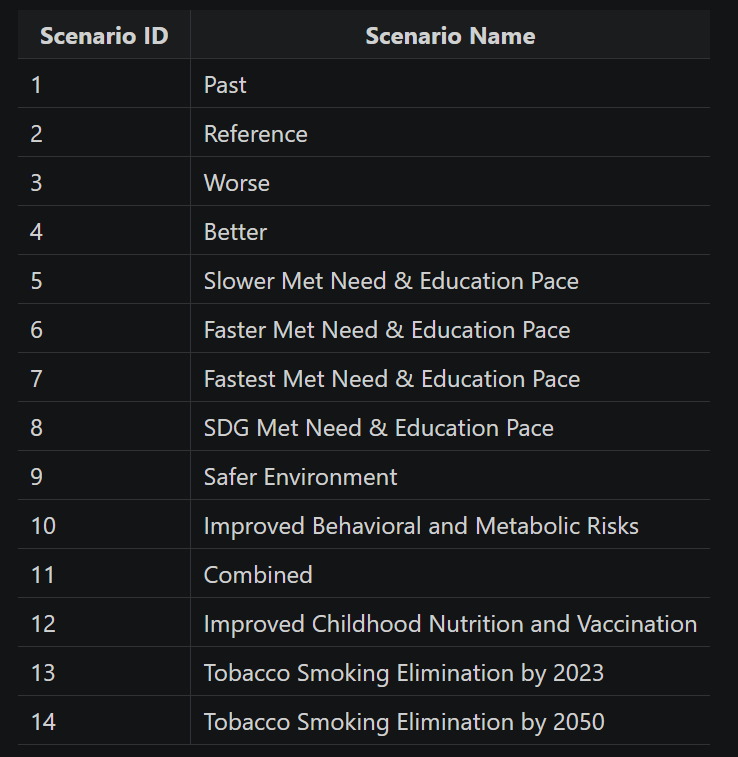

In [55]:
# Let's start with the forecasted reference scenario for 2030
air_pm_sev_ref = get_outputs(
    "rei",
    rei_id=86,
    location_id=570,
    release_id=6,
    measure_id=29,
    metric_id=3,
    year_id=2030,
    forecasted=True,
    scenario_id=2,
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
air_pm_sev_ref

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/db_queries/legacy/get_outputs_helpers/formatting.py:263: UserWarning: When looking for rei_names, we are missing values given rei_set_id: 21. Filling with latest names from rei db table. WARNING: Be very careful if sharing these results with collaborators!!
  warnings.warn(


,age_group_id,location_id,measure_id,metric_id,rei_id,scenario_id,sex_id,year_id,age_group_name,expected,...,location_type,measure,measure_name,metric_name,rei,rei_name,sex,val,upper,lower
0,16,570,29,3,86,2,1,2030,55 to 59,False,...,admin1,sev,Summary exposure value,Rate,air_pm,Ambient particulate matter pollution,Male,0.037311,0.069318,0.012629


In [56]:
air_pm_rr_max

,rei_id,cause_id,age_group_id,sex_id,draw_0,draw_1,draw_2,draw_3,draw_4,draw_5,...,draw_491,draw_492,draw_493,draw_494,draw_495,draw_496,draw_497,draw_498,draw_499,model_version_id
92,86,493,16,1,1.918678,1.800007,1.757989,2.032657,1.799113,1.819618,...,1.741957,1.823599,2.039603,2.123668,1.906066,2.015574,1.977034,1.957229,1.879274,470
122,86,495,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470
152,86,496,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470
182,86,497,16,1,1.894618,1.772149,1.859285,1.719785,1.852701,1.701156,...,1.788171,1.765323,1.687746,1.784366,1.705839,1.813704,1.788861,1.800374,1.868763,470


In [58]:
air_pm_paf_ref = 0.0373*(1.919-1) / (1 + 0.0373*(1.919-1))
air_pm_paf_ref 

0.03314261426828185

In [53]:
total_cvd_deaths_ref = get_outputs(
    "cause",
    cause_id=491,
    location_id=570,
    release_id=6,
    measure_id=1,
    metric_id=1,
    year_id=2030,
    forecasted=True,
    scenario_id=2,
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
total_cvd_deaths_ref  # Can specify sex and age groups 

,age_group_id,cause_id,location_id,measure_id,metric_id,scenario_id,sex_id,year_id,acause,age_group_name,...,expected,location_name,location_type,measure,measure_name,metric_name,sex,val,upper,lower
0,16,491,570,1,1,2,1,2030,cvd,55 to 59,...,False,Washington,admin1,death,Deaths,Number,Male,361.772127,477.702179,263.279011


In [60]:
361.772 * 0.03314

11.98912408

In [61]:
sev_safer = get_outputs(
    "rei",
    rei_id=86,
    location_id=570,
    release_id=6,
    measure_id=29,
    metric_id=3,
    year_id=2030,
    forecasted=True,
    scenario_id=9,
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
sev_safer

# At least currently we only have the Reference Scenario and the Safer Environment Scenario

/ihme/homes/pletale/.conda/envs/vivarium_gates_mncnh/lib/python3.11/site-packages/db_queries/legacy/get_outputs_helpers/formatting.py:263: UserWarning: When looking for rei_names, we are missing values given rei_set_id: 21. Filling with latest names from rei db table. WARNING: Be very careful if sharing these results with collaborators!!
  warnings.warn(


,age_group_id,location_id,measure_id,metric_id,rei_id,scenario_id,sex_id,year_id,age_group_name,expected,...,location_type,measure,measure_name,metric_name,rei,rei_name,sex,val,upper,lower
0,16,570,29,3,86,9,1,2030,55 to 59,False,...,admin1,sev,Summary exposure value,Rate,air_pm,Ambient particulate matter pollution,Male,0.028203,0.051182,0.009406


In [63]:
air_pm_paf_safer = 0.0282*(1.919-1) / (1 + 0.0282*(1.919-1))
air_pm_paf_safer

0.02526113741498084

In [62]:
deaths_safer = get_outputs(
    "cause",
    cause_id=491,
    location_id=570,
    release_id=6,
    measure_id=1,
    metric_id=1,
    year_id=2030,
    forecasted=True,
    scenario_id=9,    
    sex_id=1,  
    age_group_id=16,  # 55-59 years
)
deaths_safer

,age_group_id,cause_id,location_id,measure_id,metric_id,scenario_id,sex_id,year_id,acause,age_group_name,...,expected,location_name,location_type,measure,measure_name,metric_name,sex,val,upper,lower
0,16,491,570,1,1,9,1,2030,cvd,55 to 59,...,False,Washington,admin1,death,Deaths,Number,Male,360.511015,476.117065,262.355047


In [64]:
360.511015 * 0.02526

9.1065082389

# Next steps

- Update calculation to include all age groups and sexes in Washington State in 2021 and 2030, instead of just 55-59 year-old males.
- Update code to use indexed dataframes instead of hardcoded values.
- Add plotting code that compares the number of deaths across age groups and sexes between the two scenarios.
- Look into FHS methodology re: how they calculate air pollution SEVs and what is included in the calculation.
- See if we can bend risk exposure curve on reference scenario, using an exposure distribution that matches the FHS SEV, using risk distributions repo (https://github.com/ihmeuw/risk_distributions) to find a solution that translates from the FHS SEV to an actual RF distribution (?)